In [64]:
from typing import Optional, Tuple
from otter.io.data_finder import DataFinder
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.table import Table
from astropy.io.votable import parse_single_table
from urllib.request import urlopen
import io
from astropy.time import Time

gw190521_trigger_time = Time("2019-05-21 03:02:29")

In [114]:
def query_ztf(ra, dec, radius=2, mjd_min=58200, mjd_max=58900):
        """
        Query ZTF photometry/forced photometry for photometry for this host

        Args:
            radius (float) : The search radius in arcseconds

        Returns:
            An astropy table of the time series data from the cone search in ZTF
        """

        base_url = "https://irsa.ipac.caltech.edu/cgi-bin/ZTF/nph_light_curves?"

        search_radius_arcseconds = radius  # in arcseconds
        search_radius_degree = search_radius_arcseconds / 3600

        query_url = f"{base_url}POS=CIRCLE%20{ra}%20{dec}%20{search_radius_degree}&TIME={mjd_min}%20{mjd_max}&BANDNAME=r&BAD_CATFLAGS_MASK=32768"

        resp = urlopen(query_url)

        votab = parse_single_table(io.BytesIO(resp.read()))

        return Table(votab.array)

def _stack_data(df, cadence=5, sig=3, by=("filtercode",)):
    """
    Stack photometry into bins of `cadence` days.
    Averages in flux space with inverse-variance weights, optionally
    sigma-clipping within each bin, then converts back to magnitudes.
    `by`: extra columns to group on (e.g. filter), so bands aren't mixed.
    """
    df = df.copy()
    # mag -> flux (zero point cancels when converting back)
    df["flux"] = 10 ** (-0.4 * df.mag)
    df["fluxerr"] = df.flux * df.magerr * np.log(10) / 2.5

    edges = np.arange(df.mjd.min(), df.mjd.max() + cadence, cadence)
    df["bin"] = pd.cut(df.mjd, edges, right=False)   # [a, b): keeps the first point

    def combine(g):
        if sig and len(g) > 2:                        # simple sigma clip about the median
            z = np.abs(g.flux - np.median(g.flux)) / g.fluxerr
            g = g[z < sig] if (z < sig).any() else g
        w = 1 / g.fluxerr ** 2
        return pd.Series({
            "mjd": np.sum(w * g.mjd) / np.sum(w),
            "flux": np.sum(w * g.flux) / np.sum(w),
            "fluxerr": 1 / np.sqrt(np.sum(w)),
            "n": len(g),
        })

    keys = [*by, "bin"] if by else ["bin"]
    out = df.groupby(keys, observed=True).apply(combine).reset_index()

    out["mag"] = -2.5 * np.log10(out.flux)
    out["magerr"] = 2.5 / np.log(10) * out.fluxerr / out.flux
    return out


def detect_flare(
    postphot: Optional[pd.DataFrame],
    baseline: dict,
    corroboration_window_days: float = 0.5,
    pair_max_gap_days: float = 0.0,
):
    # each night's peak corroborated significance, capped by its better adjacent observed
    # night when one lies within pair_max_gap_days, and an isolated night counts as it is.
    phot = _flare_significance_series(postphot, baseline, corroboration_window_days)
    if phot is None:
        return np.nan, None
    night = np.floor(phot.mjd.to_numpy(dtype=float)) if "mjd" in phot.columns else np.arange(len(phot))
    peaks = phot.significance_corroborated.groupby(night).idxmax()  # sorted by night
    nights = peaks.index.to_numpy(dtype=float)
    nightly = phot.significance_corroborated.loc[peaks].to_numpy()
    best, limiting = -np.inf, 0
    for i in range(len(nightly)):
        near = [j for j in (i - 1, i + 1)
                if 0 <= j < len(nightly) and abs(nights[j] - nights[i]) <= pair_max_gap_days]
        j = max(near, key=lambda n: nightly[n]) if near else i
        weaker = i if nightly[i] <= nightly[j] else j
        if nightly[weaker] > best:
            best, limiting = nightly[weaker], weaker
    return float(best), phot.loc[peaks.iloc[limiting]]

def _flare_significance_series(
    postphot: Optional[pd.DataFrame],
    baseline: dict,
    corroboration_window_days: float = 0.5,
) -> Optional[pd.DataFrame]:
    # Returns list of photometry points --> z-scores compared to pre-merger baseline
    if postphot is None or not len(postphot) or not baseline:
        return None

    phot = postphot[~postphot.upperlimit]
    phot = phot[phot["filter"].isin(baseline.keys())]
    if not len(phot):
        return None

    # Adding photometry error with baseline's error in quadrature
    # significance is just a z-score
    significance = [
        (baseline[row["filter"]]["mag"] - row.mag)
        / np.sqrt(baseline[row["filter"]]["std"] ** 2 + row.magerr**2)
        for _, row in phot.iterrows()
    ]
    phot = phot.assign(significance=significance)
    return phot.assign(
        significance_corroborated=_corroborated_significance(
            phot, corroboration_window_days
        )
    )

def _corroborated_significance(
    phot: pd.DataFrame, window_days: float
) -> np.ndarray:
    sig = phot.significance.to_numpy(dtype=float)

    times = None
    for col in ("mjd", "dt"):
        if col in phot.columns:
            times = phot[col].to_numpy(dtype=float)
            break
    if times is None:
        # Only hand-built frames reach this; real photometry always carries mjd.
        return sig

    filters = phot["filter"].to_numpy()
    out = np.empty(sig.size, dtype=float)
    for i in range(sig.size):
        near = (filters == filters[i]) & (np.abs(times - times[i]) <= window_days)
        out[i] = np.median(sig[near])
    return out

def _robust_scatter(mags: np.ndarray, errs: np.ndarray) -> Tuple[float, float]:
    median_mag = float(np.median(mags))
    # 1.4826 rescales the MAD to a Gaussian sigma for normally distributed data
    robust_std = 1.4826 * float(np.median(np.abs(mags - median_mag)))
    median_err = float(np.median(errs))
    return max(robust_std, median_err), median_err


def fit_agn_baseline(
    prephot: Optional[pd.DataFrame], min_baseline_pts: int = 2,
) -> dict:
    # baseline has keys of filters, and the values are a dictionary that
    # includes the median magnitude, and a measure of the deviation of points
    # which is photometric errors or adjusted-MAD
    baseline = {}
    # prephot is all of the photometry data before GW detection
    if prephot is None or not len(prephot):
        return baseline

    phot = prephot[~prephot.upperlimit]
    for filt, group in phot.groupby("filter"):
        mags = group.mag.to_numpy(dtype=float)
        if len(mags) < min_baseline_pts:
            continue
        median_mag = float(np.median(mags))
        robust_std, median_err = _robust_scatter(
            mags, group.magerr.to_numpy(dtype=float)
        )
        baseline[filt] = dict(
            mag=median_mag, std=robust_std, n=int(len(mags)), median_err=median_err,
        )
    return baseline


In [115]:
name = "ZTF19abanrhr"
ra, dec = 192.4262216, 34.8247237

df = query_ztf(ra, dec).to_pandas()

In [116]:
# bin the light curve
_stack_data(df)

,filtercode,bin,mjd,flux,fluxerr,n,mag,magerr
0,zr,"[58216.241, 58221.241)",58217.903434,2.684890e-08,3.837290e-10,19.0,18.927684,0.015518
1,zr,"[58221.241, 58226.241)",58222.957949,2.743362e-08,4.668946e-10,13.0,18.904292,0.018478
2,zr,"[58226.241, 58231.241)",58228.106450,2.661367e-08,6.845774e-10,6.0,18.937238,0.027928
3,zr,"[58231.241, 58236.241)",58232.373376,2.609755e-08,6.284837e-10,7.0,18.958501,0.026147
4,zr,"[58241.241, 58246.241)",58243.604712,2.660829e-08,7.376050e-10,5.0,18.937458,0.030098
...,...,...,...,...,...,...,...,...
81,zr,"[58876.241, 58881.241)",58878.433334,2.822800e-08,3.622303e-10,22.0,18.873300,0.013932
82,zr,"[58881.241, 58886.241)",58883.639371,2.823327e-08,3.988239e-10,18.0,18.873097,0.015337
83,zr,"[58886.241, 58891.241)",58888.122734,2.909260e-08,4.563874e-10,14.0,18.840544,0.017032
84,zr,"[58891.241, 58896.241)",58893.361817,2.809323e-08,3.532163e-10,23.0,18.878496,0.013651


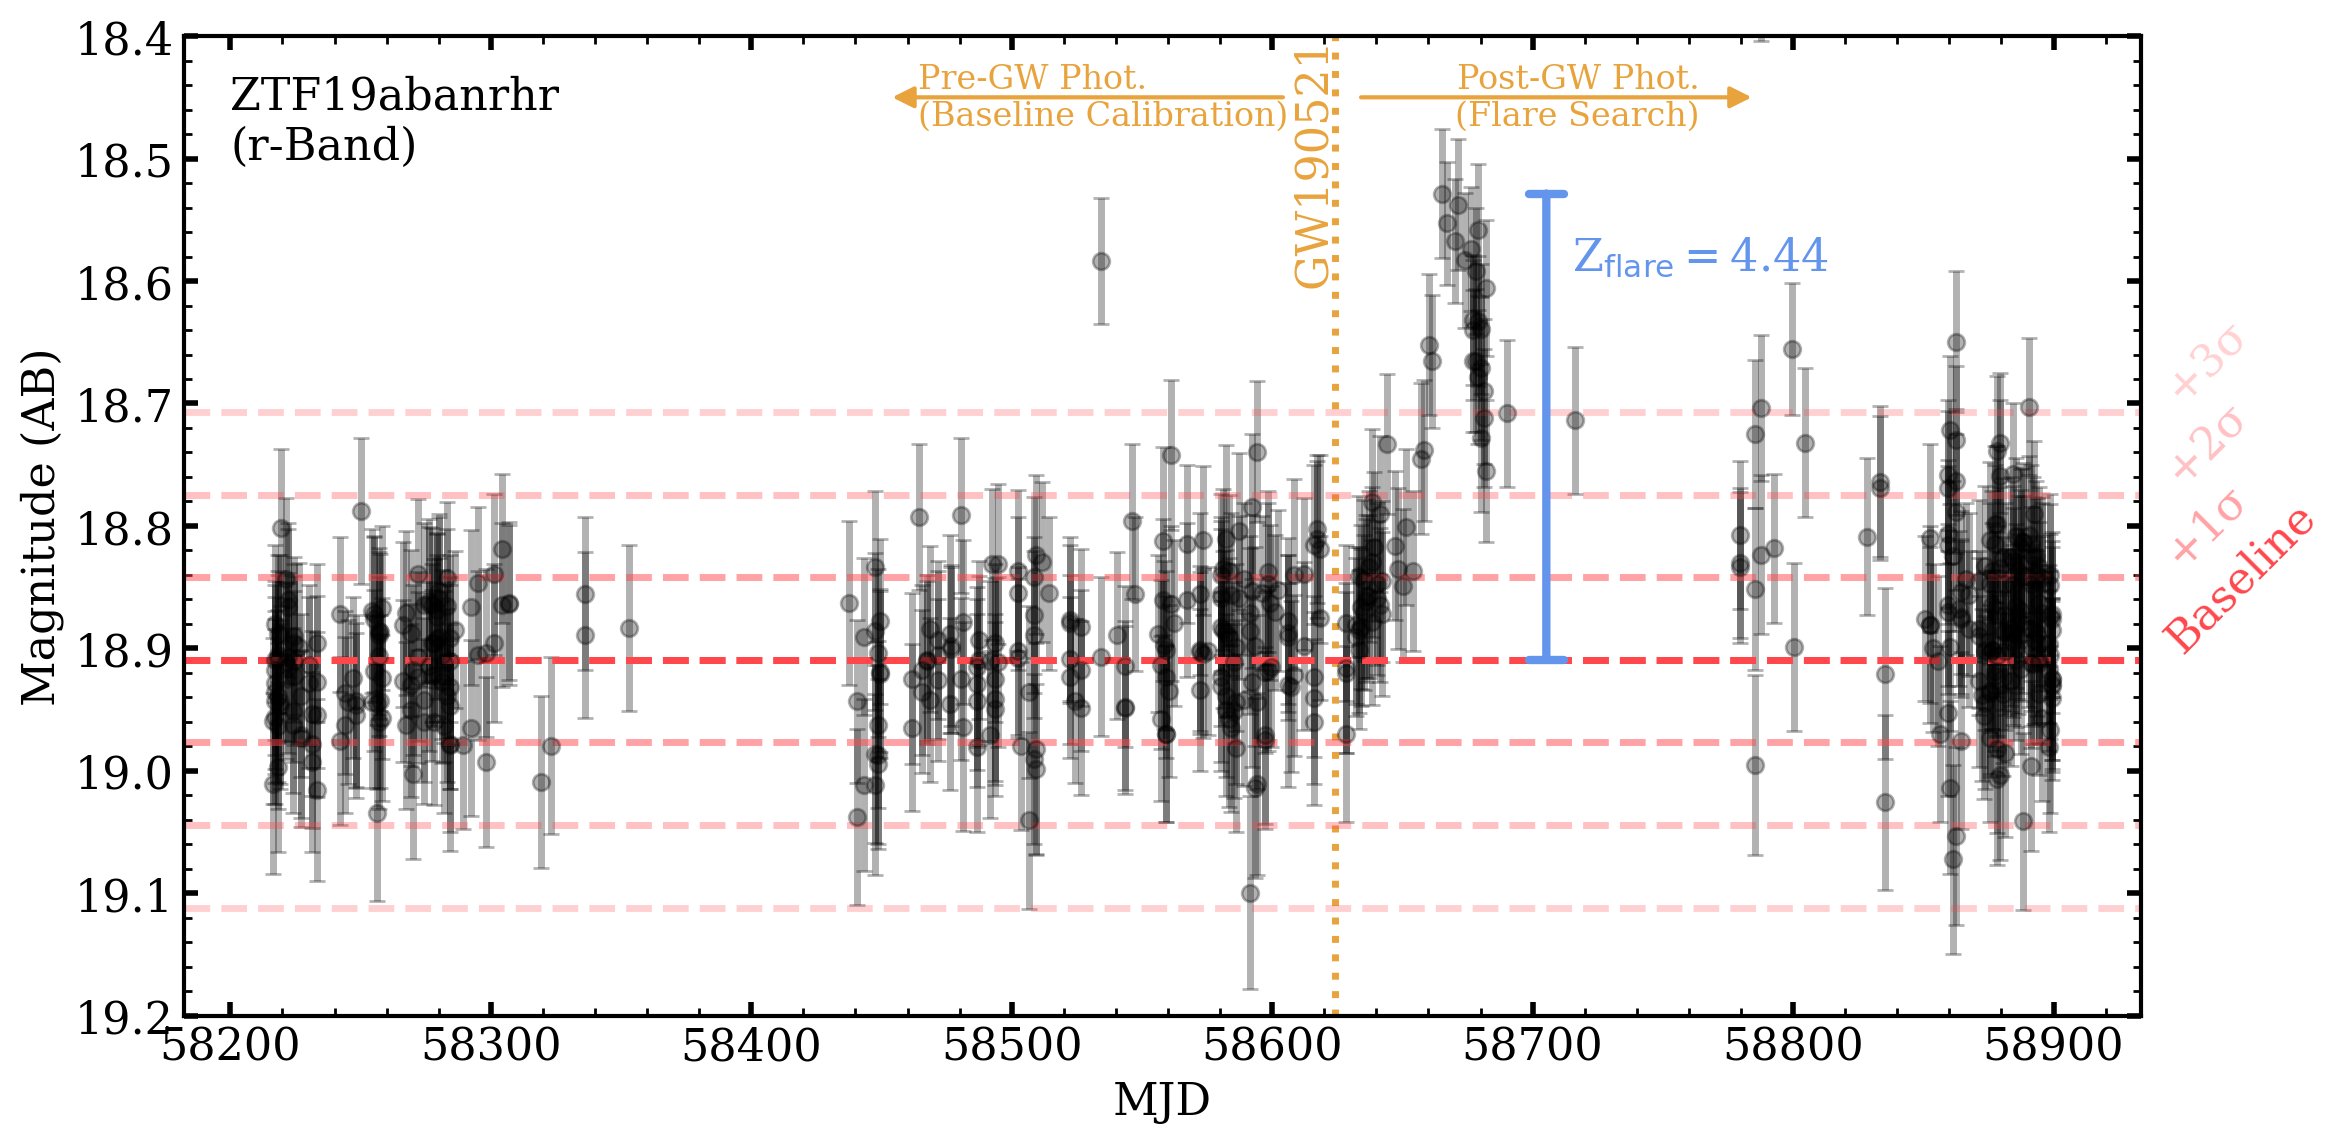

In [165]:
fig, ax = plt.subplots(figsize=(12,6))

rlc = df #_stack_data(df, cadence=5)
rlc["upperlimit"] = False
rlc["filter"] = rlc.filtercode

ax.errorbar(rlc.mjd, rlc.mag, yerr=rlc.magerr, marker="o", linestyle="none", alpha=0.3, color="k", label=name)

ax.set_ylabel("Magnitude (AB)")
ax.set_xlabel("MJD")
ax.set_ylim(19.2, 18.4)

gw_col = "#E8A33D"
dt = 150
y_arr = 18.45
ax.axvline(gw190521_trigger_time.mjd, linestyle=":", color=gw_col)
ax.text(gw190521_trigger_time.mjd, 18.4, "GW190521", rotation=90, va="top", ha="right", color=gw_col)
ax.annotate("", xy=(gw190521_trigger_time.mjd-20, y_arr),
            xytext=(gw190521_trigger_time.mjd-20-dt, y_arr),
            arrowprops=dict(arrowstyle="<|-,widthA=0.4,widthB=0.4",
                            color=gw_col, lw=1.5, shrinkA=0, shrinkB=0))
ax.annotate("", xy=(gw190521_trigger_time.mjd+10, y_arr),
            xytext=(gw190521_trigger_time.mjd+10+dt, y_arr),
            arrowprops=dict(arrowstyle="<|-,widthA=0.4,widthB=0.4",
                            color=gw_col, lw=1.5, shrinkA=0, shrinkB=0))
ax.text(gw190521_trigger_time.mjd-10-dt, y_arr, "Pre-GW Phot.\n(Baseline Calibration)", ha="left", va="center", fontsize=12, color=gw_col)
ax.text(gw190521_trigger_time.mjd-10+dt, y_arr, "Post-GW Phot.\n(Flare Search)", ha="right", va="center", fontsize=12, color=gw_col)


# plot some model related things
prephot = rlc[rlc.mjd <= gw190521_trigger_time.mjd]
postphot = rlc[rlc.mjd > gw190521_trigger_time.mjd]

baseline_dict = fit_agn_baseline(prephot)
sig, sig_pt = detect_flare(postphot, baseline_dict)

baseline_med = baseline_dict['zr']['mag'] 
baseline_std = baseline_dict['zr']['std']

baseline_color = "#FF474C"
for i, label in zip([0, 1,2,3], ["Baseline", r"+1$\sigma$", r"+2$\sigma$", r"+3$\sigma$"]):
    ax.axhline(baseline_med-i*baseline_std, alpha=1/(i+1), linestyle="--", color=baseline_color)
    ax.axhline(baseline_med+i*baseline_std, alpha=1/(i+1), linestyle="--", color=baseline_color)
    ax.text(58940, baseline_med-i*baseline_std, label, alpha=1/(i+1), rotation=45, color=baseline_color, ha="left", va="bottom")

x = sig_pt.mjd+40
col = "cornflowerblue"
ax.annotate("", xy=(x, baseline_med),
            xytext=(x, sig_pt.mag),
            arrowprops=dict(arrowstyle="|-|,widthA=0.4,widthB=0.4",
                            color=col, lw=3, shrinkA=0, shrinkB=0))
ax.text(x+10, 18.58, rf"$Z_{{\rm flare}}={sig:.2f}$", color=col, ha="left", va="center")

ax.text(58200, 18.5, name+"\n(r-Band)", ha="left")

fig.savefig("agn-flare-phot-score.png", dpi=200)

18.40270631787834

{'zr': {'mag': 18.90704345703125,
  'std': 0.0673014372587204,
  'n': 343,
  'median_err': 0.0673014372587204}}

(7.493705330751486,
 oid                          672209100002601
 expid                               94120343
 hjd                           2458695.700449
 mjd                             58695.203438
 mag                                18.312788
 magerr                              0.041942
 catflags                               32768
 filtercode                                zr
 ra                                192.426485
 dec                                34.824724
 chi                                    1.078
 sharp                                 -0.328
 filefracday                   20190731203438
 field                                    672
 ccdid                                      9
 qid                                        1
 limitmag                           18.690001
 magzp                              24.610563
 magzprms                             0.06907
 clrcoeff                            0.131223
 clrcounc                             0.00032
 exptime      

In [79]:
significance = [
    (baseline_dict[row["filter"]]["mag"] - row.mag)
    / np.sqrt(baseline_dict[row["filter"]]["std"] ** 2 + row.magerr**2)
    for _, row in postphot.iterrows()
]
significance

[-0.226563924450402,
 0.3120305972531164,
 0.4883096761919012,
 0.4717969485896361,
 0.820827538324011,
 0.9381659544594025,
 1.3151482340915561,
 1.0624806806162295,
 0.8033029976205183,
 1.0436567834587132,
 0.7520989031080857,
 2.320829212177284,
 1.2443860107506153,
 0.734359232382249,
 1.319426838135737,
 0.8583884115586103,
 2.5835414392429663,
 3.3874641997367294,
 3.3154733048712206,
 5.276491302409216,
 5.090244455536601,
 4.858579580495682,
 5.131790982872913,
 4.421864809879821,
 4.750456080694147,
 4.501506305986398,
 4.544703368291582,
 4.882338831792984,
 3.9130010101991353,
 3.2461909651043106,
 3.5199563316654077,
 4.111702300993267,
 2.5812005707133467,
 9.284918542458506,
 2.5010797886097182,
 1.3854967469430752,
 0.8072179886857036,
 2.1897293956291892,
 1.1376689446900274,
 3.4748159671338468,
 0.09439098804328139,
 2.2443525584242696,
 1.2177705525032403,
 2.1762003720029575,
 -0.9954718450038127,
 0.5094633265225266,
 0.3728079517767326,
 0.7131711641229861,
 0.08